# Импроты и константы



In [22]:
import os
import time
import json
import requests
import pandas as pd
from datetime import datetime, timezone
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

pd.options.mode.chained_assignment = None

# Константы (Вариант 3)
SEARCH_API = "https://openlibrary.org/search.json"
AUTHOR_API = "https://openlibrary.org/authors/{}.json"
QUERY = "fantasy"

RAW_FILE = "data_raw.jsonl"
CLEAN_FILE = "data_clean.csv"
LOG_FILE = "collection_log.csv"
STATE_FILE = "state.json"

# Сессия

In [23]:
def make_session(total_retries=5):
    session = requests.Session()
    retry = Retry(
        total=total_retries,
        backoff_factor=1.0,
        status_forcelist=[429, 500, 502, 503, 504], # Для 4xx повторы запрещены
        allowed_methods=["GET"],
        respect_retry_after_header=True
    )
    adapter = HTTPAdapter(max_retries=retry)
    session.mount("https://", adapter)
    session.mount("http://", adapter)

    session.headers.update({
        "User-Agent": "student-lab3-data-collector/1.0",
        "Accept": "application/json"
    })
    return session

def safe_request(session, url, params=None, timeout=15):
    start_time = time.time()
    try:
        response = session.get(url, params=params, timeout=timeout)
        duration = round(time.time() - start_time, 3)
        response.raise_for_status()

        if "application/json" not in response.headers.get("Content-Type", ""):
            print(f"Ошибка: Неверный Content-Type от {url}")
            return None, response.status_code, duration

        return response.json(), response.status_code, duration

    except requests.exceptions.RequestException as e:
        duration = round(time.time() - start_time, 3)
        error_body = e.response.text[:200] if e.response is not None else str(e)
        status = e.response.status_code if e.response is not None else 0
        print(f"Сетевая ошибка (статус {status}): {error_body}")
        return None, status, duration

In [24]:
session = make_session()
print("Тестовый запрос к API...")
test_data, status, duration = safe_request(session, SEARCH_API, {"q": "test", "limit": 1})
print(f"Статус: {status}, Время: {duration}с. Ключи: {list(test_data.keys()) if test_data else 'Ошибка'}")

Тестовый запрос к API...
Статус: 200, Время: 0.678с. Ключи: ['numFound', 'start', 'numFoundExact', 'num_found', 'documentation_url', 'q', 'offset', 'docs']


# Сбор данных

In [25]:
def load_state():
    if os.path.exists(STATE_FILE):
        with open(STATE_FILE, "r", encoding="utf-8") as f:
            state = json.load(f)
            # Добавляем структуру для авторов, если читаем старый файл состояния
            if "authors_cache" not in state:
                state["authors_cache"] = {}
            return state
    return {"last_page": 0, "processed_keys": [], "authors_cache": {}}

def save_state(state):
    with open(STATE_FILE, "w", encoding="utf-8") as f:
        json.dump(state, f, ensure_ascii=False, indent=2)

In [26]:
def fetch_books_paginated(session, max_records_total=300, max_pages=15, page_size=100):
    state = load_state()
    start_page = state["last_page"] + 1
    already_collected = len(state["processed_keys"])

    print(f"Всего в базе уже {already_collected} записей. Целевой объем: {max_records_total}")

    if already_collected >= max_records_total:
        print("Требуемый объем данных уже собран. Дополнительный сбор не требуется.")
        return

    records_needed = max_records_total - already_collected
    records_collected_this_run = 0
    logs = []

    print(f"--- Старт сбора со страницы {start_page}. Осталось собрать: {records_needed} ---")

    mode = "a" if start_page > 1 else "w"
    with open(RAW_FILE, mode, encoding="utf-8") as raw_f:
        for page in range(start_page, start_page + max_pages):
            if records_collected_this_run >= records_needed:
                print(f"Достигнут заданный лимит записей ({max_records_total} всего).")
                break

            params = {"q": QUERY, "page": page, "limit": page_size}

            # Обязательная пауза (ограничитель скорости)
            time.sleep(1.5)
            data, status, duration = safe_request(session, SEARCH_API, params)

            # Логируем запрос вместе с параметрами
            logs.append({
                "page": page,
                "url": SEARCH_API,
                "params": json.dumps(params),
                "status_code": status,
                "records_count": len(data.get("docs", [])) if data else 0,
                "duration_sec": duration,
                "timestamp": datetime.now(timezone.utc).isoformat()
            })

            if not data or not data.get("docs"):
                print("Пустая страница. Остановка.")
                break

            docs = data["docs"]
            new_records = 0

            for doc in docs:
                # Проверяем инкрементальность: запись действительно новая?
                if doc.get("key") not in state["processed_keys"]:
                    # Добавляем строгую проверку, чтобы не скачать лишнего сверх target
                    if records_collected_this_run < records_needed:
                        raw_f.write(json.dumps(doc) + "\n")
                        state["processed_keys"].append(doc.get("key"))
                        new_records += 1
                        records_collected_this_run += 1

            state["last_page"] = page
            save_state(state) # Обновляем водяной знак

            print(f"Стр. {page}: получено с API {len(docs)}, сохранено новых {new_records}")

            if data.get("numFound", 0) <= page * page_size:
                print("Достигнут конец доступных данных на сервере.")
                break

    # Выгрузка журнала
    if logs:
        log_df = pd.DataFrame(logs)
        # Если файл лога уже существует и мы не на первой странице - дописываем, иначе создаем
        log_df.to_csv(LOG_FILE, mode='a' if start_page > 1 else 'w', header=not (start_page > 1), index=False)

    all_records = []
    if os.path.exists(RAW_FILE):
        with open(RAW_FILE, "r", encoding="utf-8") as f:
            for line in f:
                all_records.append(json.loads(line))

    df_raw = pd.DataFrame(all_records)
    return df_raw

In [27]:
df_fetch = fetch_books_paginated(session, max_records_total=200, max_pages=10, page_size=50)

Всего в базе уже 300 записей. Целевой объем: 200
Требуемый объем данных уже собран. Дополнительный сбор не требуется.


In [28]:
df_fetch = fetch_books_paginated(session, max_records_total=300, max_pages=10, page_size=50)

Всего в базе уже 300 записей. Целевой объем: 300
Требуемый объем данных уже собран. Дополнительный сбор не требуется.


In [29]:
df_fetch

# Нормализация

In [30]:
# Чтение сырых данных
raw_data = []
if os.path.exists(RAW_FILE):
    with open(RAW_FILE, "r", encoding="utf-8") as f:
        for line in f:
            raw_data.append(json.loads(line))

    # Оставляем записи, где указан автор
    valid_data = [doc for doc in raw_data if 'author_key' in doc]

    # Нормализация
    df = pd.json_normalize(
        valid_data,
        record_path=['author_key'],
        meta=['key', 'title', 'first_publish_year', 'language'],
        record_prefix='author_',
        sep='_',
        errors='ignore'
    )
    df.rename(columns={'author_0': 'author_key'}, inplace=True)

In [31]:
df

,author_key,key,title,first_publish_year,language
0,OL666139A,/works/OL3775422W,Fantasy Girl,1983,"[und, eng]"
1,OL661093A,/works/OL3759099W,Her Christmas Fantasy,1996,[eng]
2,OL451969A,/works/OL2959228W,Fantasy,1985,[eng]
3,OL59362A,/works/OL733144W,My Secret Garden,1973,"[dut, chi, fre, hrv, eng]"
4,OL18977A,/works/OL14873636W,Fantasy in death,2010,"[fre, eng]"
...,...,...,...,...,...
959,OL1391674A,/works/OL17733528W,Fantasy Man,1988,[eng]
960,OL2853241A,/works/OL19913885W,Afrofuturism: The World of Black Sci-Fi and Fa...,2013,[eng]
961,OL2798003A,/works/OL17736567W,A visit to Fairyland,2004,[eng]
962,OL23105A,/works/OL15593W,The illusionless man,1966,[eng]


# Обогащение

In [32]:
def enrich_author(session, author_key):
    if not author_key: return None
    url = AUTHOR_API.format(author_key)
    time.sleep(0.5) # Пауза перед обогащением

    data, status, _ = safe_request(session, url)
    if status == 200 and data:
        return {
            "author_key": author_key,
            "author_name": data.get("name"),
            "fuller_name": data.get("fuller_name"),
            "birth_date": data.get("birth_date"),
        }
    return None

In [33]:
# Дедупликация
duplicates_count = df.duplicated(subset=['key', 'author_key']).sum()
print(f"Найдено дубликатов: {duplicates_count}")
print(f"Дубликаты: {df[df.duplicated(subset=['key', 'author_key'], keep=False)].sort_values(by=['key', 'author_key'])}")
df_dedup = df.drop_duplicates(subset=['key', 'author_key']).copy()

Найдено дубликатов: 2
Дубликаты:     author_key                 key                        title  \
419   OL19593A  /works/OL17485033W  The Urban Fantasy Anthology   
427   OL19593A  /works/OL17485033W  The Urban Fantasy Anthology   
428   OL19593A  /works/OL17485033W  The Urban Fantasy Anthology   

    first_publish_year language  
419               2011    [eng]  
427               2011    [eng]  
428               2011    [eng]  


In [34]:
unique_authors = df_dedup['author_key'].dropna().unique()
authors_data = []

In [35]:
unique_authors = df_dedup['author_key'].dropna().unique()

# Загружаем состояние
state = load_state()

new_authors_count = 0

for auth_key in unique_authors:
    # Проверяем наличие автора в state.json
    if auth_key not in state["authors_cache"]:
        info = enrich_author(session, auth_key)
        if info:
            state["authors_cache"][auth_key] = info
            new_authors_count += 1

            # Сохраняем обновленное состояние в state.json
            save_state(state)

print(f"Запрошено новых авторов в этой сессии: {new_authors_count}")

# Извлекаем только тех авторов, которые есть в текущей выборке
current_authors_data = [state["authors_cache"][k] for k in unique_authors if k in state["authors_cache"]]
df_authors = pd.DataFrame(current_authors_data)

rows_before = len(df_dedup)
if not df_authors.empty:
    df_final = df_dedup.merge(df_authors, on='author_key', how='left')
else:
    df_final = df_dedup

print(f"Проверка merge -> Строк до: {rows_before}, строк после: {len(df_final)}")

Запрошено новых авторов в этой сессии: 670
Проверка merge -> Строк до: 962, строк после: 962


In [36]:
df_final

,author_key,key,title,first_publish_year,language,author_name,fuller_name,birth_date
0,OL666139A,/works/OL3775422W,Fantasy Girl,1983,"[und, eng]",Carole Mortimer,"Mortimer, Carole",1960
1,OL661093A,/works/OL3759099W,Her Christmas Fantasy,1996,[eng],Penny Jordan,NaN,24 November 1946
2,OL451969A,/works/OL2959228W,Fantasy,1985,[eng],Emma Darcy,NaN,NaN
3,OL59362A,/works/OL733144W,My Secret Garden,1973,"[dut, chi, fre, hrv, eng]",Nancy Friday,NaN,NaN
4,OL18977A,/works/OL14873636W,Fantasy in death,2010,"[fre, eng]",Nora Roberts,"Robertson Aufdem-Brinke Wilder, Eleanor Marie","October 10, 1950"
...,...,...,...,...,...,...,...,...
957,OL1391674A,/works/OL17733528W,Fantasy Man,1988,[eng],Paula Detmer Riggs,NaN,1944
958,OL2853241A,/works/OL19913885W,Afrofuturism: The World of Black Sci-Fi and Fa...,2013,[eng],Ytasha Womack,NaN,NaN
959,OL2798003A,/works/OL17736567W,A visit to Fairyland,2004,[eng],Shirley Barber,NaN,NaN
960,OL23105A,/works/OL15593W,The illusionless man,1966,[eng],Allen Wheelis,NaN,23 Oct 1915


In [37]:
df_final[df_final['fuller_name'].notna()]

,author_key,key,title,first_publish_year,language,author_name,fuller_name,birth_date
0,OL666139A,/works/OL3775422W,Fantasy Girl,1983,"[und, eng]",Carole Mortimer,"Mortimer, Carole",1960
4,OL18977A,/works/OL14873636W,Fantasy in death,2010,"[fre, eng]",Nora Roberts,"Robertson Aufdem-Brinke Wilder, Eleanor Marie","October 10, 1950"
17,OL29586A,/works/OL109229W,The ghost,1907,[eng],Arnold Bennett,Enoch Arnold Bennett,27 May 1867
27,OL19905A,/works/OL80865W,Castle Roogna,1979,[eng],Piers Anthony,Piers Anthony Dillingham Jacob,6 August 1934
37,OL28641A,/works/OL1960531W,The Fantasy Hall of Fame [30 stories],1985,[eng],Robert A. Heinlein,Robert Anson Heinlein,7 July 1907
38,OL34434A,/works/OL1960531W,The Fantasy Hall of Fame [30 stories],1985,[eng],James Blish,James Benjamin Blish,23 May 1921
41,OL24562A,/works/OL1960531W,The Fantasy Hall of Fame [30 stories],1985,[eng],Theodore Sturgeon,Thodore H. Sturgeon,26 February 1918
42,OL227499A,/works/OL1960531W,The Fantasy Hall of Fame [30 stories],1985,[eng],Avram Davidson,Avram James Davidson,23 April 1923
44,OL1684660A,/works/OL1960531W,The Fantasy Hall of Fame [30 stories],1985,[eng],Robert Bloch,Robert Albert Bloch,5 April 1917
47,OL402789A,/works/OL1960531W,The Fantasy Hall of Fame [30 stories],1985,[eng],J. G. Ballard,James Graham Ballard,15 November 1930


# Проверка качества
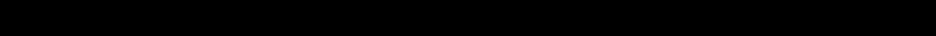

In [38]:
# Приведение типов
df_final['first_publish_year'] = pd.to_numeric(df_final['first_publish_year'], errors='coerce')
df_final['birth_date'] = pd.to_datetime(df_final['birth_date'], errors='coerce', utc=True)
df_final['birth_date'] = df_final['birth_date'].dt.strftime('%Y-%m-%d')

In [39]:
valid_title_mask = df_final['title'].notna() & (df_final['title'].astype(str).str.strip() != '')
passed_title = valid_title_mask.sum()
failed_title = (~valid_title_mask).sum()
print(f"1. Название заполнено: {passed_title} | Пусто: {failed_title}")

current_year = datetime.now().year
valid_year_mask = df_final['first_publish_year'] <= current_year
passed_year = valid_year_mask.sum()
not_year = df_final['first_publish_year'].isna().sum()
print(f"2. Корректный год издания: {passed_year} | Пусто: {not_year}")

1. Название заполнено: 962 | Пусто: 0
2. Корректный год издания: 938 | Пусто: 24


In [40]:
# Качество данных
completeness = (df_final.notnull().sum() / len(df_final)) * 100
print("\nКачество данных - Полнота полей (%):")
print(completeness.round(2))


Качество данных - Полнота полей (%):
author_key            100.00
key                   100.00
title                 100.00
first_publish_year     97.51
language               98.34
author_name           100.00
fuller_name             4.99
birth_date             16.63
dtype: float64


In [41]:
# Выгрузка
df_final.to_csv(CLEAN_FILE, index=False)
print(f"\nДанные сохранены в {CLEAN_FILE}. Итого строк: {len(df_final)}")


Данные сохранены в data_clean.csv. Итого строк: 962
